In [1]:
import pandas as pd
import numpy as np

## Corpus text analysis

In [3]:
from driver import clean_text

corpus = pd.read_excel("Data/corpus.xlsx")
corpus["text_content"] = corpus["text_content"].apply(lambda x: clean_text(x))
corpus.head()

,doc_id,url,html_content,text_content,scraping_source
0,d0,https://wwftravel.it/blog/viaggi/india-natura-...,"<body><p>""\n</p>\n<a class=""skip-link screen-r...",Vai al contenuto Home Blog Viaggi India natura...,manual-scraped
1,d1,https://www.terreincognitemagazine.it/natura-s...,"<body class=""single single-post postid-2526 si...",Homepage > CULTURA > MOSTRE > Natura selvaggia...,auto-scraped
2,d2,https://www.storicang.it/a/civilta-dellindo-i-...,"<body><p>""\n</p><div aria-hidden=""true"" class=...",La prospera civiltà della valle dell'Indo creb...,manual-scraped
3,d3,https://www.focusjunior.it/scuola/storia/chi-s...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Scuola Storia Chi sono gli Indi...,auto-scraped
4,d4,https://www.focusjunior.it/comportamento/feste...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Comportamento Feste Festa della...,auto-scraped


In [4]:
from driver import get_text_stats

text_stat_results = get_text_stats(corpus, "text_content")

corpus["content_len"] = text_stat_results["content_len"]
corpus["mean_aoa"] = text_stat_results["mean_aoa"]
corpus["mean_conc"] = text_stat_results["mean_conc"]
corpus["gulpease_index"] = text_stat_results["gulpease_index"]

  0%|          | 0/221 [00:00<?, ?it/s]

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [5]:
corpus.to_excel("Data/analysed_corpus.xlsx", index=False)

In [6]:
corpus.head()

,doc_id,url,html_content,text_content,scraping_source,content_len,mean_aoa,mean_conc,gulpease_index
0,d0,https://wwftravel.it/blog/viaggi/india-natura-...,"<body><p>""\n</p>\n<a class=""skip-link screen-r...",Vai al contenuto Home Blog Viaggi India natura...,manual-scraped,1389,5.314087,6.307500,51.666813
1,d1,https://www.terreincognitemagazine.it/natura-s...,"<body class=""single single-post postid-2526 si...",Homepage > CULTURA > MOSTRE > Natura selvaggia...,auto-scraped,1644,5.600471,5.939623,44.195174
2,d2,https://www.storicang.it/a/civilta-dellindo-i-...,"<body><p>""\n</p><div aria-hidden=""true"" class=...",La prospera civiltà della valle dell'Indo creb...,manual-scraped,1635,5.520000,6.553509,43.365193
3,d3,https://www.focusjunior.it/scuola/storia/chi-s...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Scuola Storia Chi sono gli Indi...,auto-scraped,1724,5.302264,5.982432,47.746429
4,d4,https://www.focusjunior.it/comportamento/feste...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Comportamento Feste Festa della...,auto-scraped,1140,4.143614,6.745545,52.684927


## Information distillation analysis

In [2]:
corpus_df = pd.read_excel("Data/analysed_corpus.xlsx")
explored_pages_df = pd.read_csv("Data/explored_pages.csv")
final_answer_df = pd.read_csv("Data/final_answer_df.csv")
results_navigation = pd.read_csv("Data/results_navigation.csv")

In [3]:
reqd_matches = {
    "g3t1": 1,
    "g3t2": 2,
    "g3t3": 5,
    "g4t1": 4,
    "g4t2": 2,
    "g4t3": 3
}

answer_accuracy = []
for _, row in final_answer_df.iterrows():
    rqd_num_matches = reqd_matches.get(row["topic_number"], None)
    answer_accuracy.append(min(row["num_answer_matches"], rqd_num_matches)/rqd_num_matches)

final_answer_df["answer_accuracy"] = answer_accuracy
final_answer_df["effective_answer"] = [int(ans_acc >= 1) for ans_acc in final_answer_df["answer_accuracy"]]
final_answer_df.to_csv("Data/final_answer_df.csv", index=None, encoding="utf8")
final_answer_df.head()

,uid,topic_number,prompt,answer,timestamp,num_answer_matches,matched_keywords,answer_accuracy,effective_answer,mean_rel_time,mean_irrel_time,num_clicks,num_unique_pages,click_accuracy,avg_concreteness,avg_aoa,avg_gulpease_index,avg_content_length
0,1,g3t3,Quali sono 5 animali tipici dell'India?,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:56:19.153,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,0,128.0225,NaN,2,1,1.0,6.307500,5.314087,51.666813,1389.0
1,1,g3t2,Qual è il nome del simbolo al centro della ban...,Il simbolo della bandiera rappresenta una ruota,2026-05-19 15:06:18.848,1,['ruota'],0.5,0,209.6020,NaN,1,1,1.0,6.177326,5.521524,43.901500,1116.0
2,1,g3t1,Come si chiama il fiume sacro agli indiani?,Il fiume gange,2026-05-19 15:10:10.812,1,['gange'],1.0,1,36.1120,NaN,1,1,1.0,6.622689,5.207799,49.490058,2037.0
3,2,g3t3,Quali sono 5 animali tipici dell'India?,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:58:07.578,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,1,313.3040,NaN,1,1,1.0,6.307500,5.314087,51.666813,1389.0
4,2,g3t2,Qual è il nome del simbolo al centro della ban...,Ruota,2026-05-19 15:10:30.790,1,['ruota'],0.5,0,64.6990,NaN,1,1,1.0,6.343939,5.055281,50.562343,867.0


In [25]:
len(final_answer_df.loc[final_answer_df["effective_answer"]==1]), len(final_answer_df)

(36, 54)

In [4]:
results_navigation.head()

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://wwftravel.it/blog/viaggi/india-natura-...,"India naturalistica, 5 animali da non perdere ...","\n Oct 31, 2023 ... La fauna selvatic...",1,1,2,2026-05-19 14:51:27.687
1,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.terreincognitemagazine.it/natura-s...,"Natura selvaggia in India, tra tigri e leoni -...","\n Feb 17, 2017 ... O dei Giganti, vi...",2,1,0,2026-05-19 14:51:27.688
2,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.storicang.it/a/civilta-dellindo-i-...,"La civiltà dell'Indo, i misteri di un popolo d...","\n Jun 5, 2023 ... Sono note cinque m...",3,0,0,2026-05-19 14:51:27.689
3,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/scuola/storia/chi-s...,"Chi sono gli Indiani d'America, i nativi ameri...","\n Jun 6, 2024 ... Chi sono, da dove ...",4,0,0,2026-05-19 14:51:27.690
4,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/comportamento/feste...,Festa della mamma: come si festeggia nel resto...,\n Il dolce tipico per celebrare ques...,5,0,0,2026-05-19 14:51:27.691


In [5]:
explored_pages_df.head()

,uid,topic_number,url,exploreType,viewDurationInSeconds,timestamp,click_time
0,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageOpened,NaN,2026-05-19 14:51:44.064,2026-05-19 14:51:43.444
1,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,76.920,2026-05-19 14:53:00.984,2026-05-19 14:51:43.444
2,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageOpened,NaN,2026-05-19 14:53:20.022,2026-05-19 14:53:19.408
3,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,179.125,2026-05-19 14:56:19.147,2026-05-19 14:53:19.408
4,1,g3t2,https://it.gov-civ-guarda.pt/flag-india,webpageOpened,NaN,2026-05-19 15:02:49.238,2026-05-19 15:02:48.776


In [6]:
explored_pages_df.loc[(explored_pages_df["exploreType"]=="webpageClosed")&(pd.isna(explored_pages_df["viewDurationInSeconds"]))]

,uid,topic_number,url,exploreType,viewDurationInSeconds,timestamp,click_time


In [ ]:
mean_rel_time = [] # average time spent on relevant resources
mean_irrel_time = [] # average time spent on irrelevant resources
mean_rel_irrel_time_ratio = [] # average of ratio of time spent on relevant resource to time spent on irreleveant resources 
num_clicks = []
num_unique_pages = []
click_accuracy = []
avg_concreteness = []
avg_gulpease_index = []
avg_aoa = []
avg_content_length = []

for _, row in final_answer_df.iterrows():
    rel_time = [] # time spent on relevant resources
    irrel_time = [] # time spent on irrelevant resources
    concreteness = []
    aoa = []
    gulpease_index = []
    content_length = []

    uid = row["uid"]
    topic_num = row["topic_number"]

    pages_explored = explored_pages_df.loc[(explored_pages_df["uid"]==uid) & (explored_pages_df["topic_number"]==topic_num) & (explored_pages_df["exploreType"]=="webpageClosed")]
    if len(pages_explored) > 0:
        for _, page in pages_explored.iterrows():
            url = page["url"]

            concreteness.append(corpus_df.loc[corpus_df["url"]==url]["mean_conc"].values[0])
            aoa.append(corpus_df.loc[corpus_df["url"]==url]["mean_aoa"].values[0])
            content_length.append(corpus_df.loc[corpus_df["url"]==url]["content_len"].values[0])
            gulpease_index.append(corpus_df.loc[corpus_df["url"]==url]["gulpease_index"].values[0])

            relevance = results_navigation.loc[(results_navigation["url"]==url)&(results_navigation["uid"]==uid)&(results_navigation["topic_number"]==topic_num)]["relevance_score"].values[0]
            if relevance == 1:
                rel_time.append(page["viewDurationInSeconds"])
            elif relevance == 0:
                # print(uid, topic_num, url, "\n")
                irrel_time.append(page["viewDurationInSeconds"])
        click_accuracy.append(len(rel_time)/len(pages_explored))
    elif len(pages_explored) == 0:
        click_accuracy.append(None)
    #     print(uid, topic_num, "no items explored")
        rel_time.append(0)
        irrel_time.append(0)
        concreteness.append(0)
        aoa.append(0)
        content_length.append(0)
        gulpease_index.append(0)

    # if (len(irrel_time) == 0) and (len(pages_explored) != 0):
    #     # print(uid, topic_num, "no irrelevant items explored.")
    #     irrel_time.append(0)
    # elif (len(rel_time) == 0) and (len(pages_explored) != 0):
    #     # print(uid, topic_num, "no relevant items explored.")
    #     rel_time.append(0)
    mean_rel_time.append(np.mean(rel_time))
    mean_irrel_time.append(np.mean(irrel_time))
    mean_rel_irrel_time_ratio.append(np.mean(rel_time)/np.mean(irrel_time))

    number_of_clicks = results_navigation.loc[(results_navigation["uid"]==uid)&(results_navigation["topic_number"]==topic_num)]["click_count"].sum()
    assert number_of_clicks == len(pages_explored)
    num_clicks.append(number_of_clicks)
    num_unique_pages.append(len(pages_explored["url"].unique().tolist()))
    avg_concreteness.append(np.mean(concreteness))
    avg_aoa.append(np.mean(aoa))
    avg_gulpease_index.append(np.mean(gulpease_index))
    avg_content_length.append(np.mean(content_length))

final_answer_df["mean_rel_time"] = mean_rel_time
final_answer_df["mean_irrel_time"] = mean_irrel_time
final_answer_df["mean_rel_irrel_time_ratio"] = mean_rel_irrel_time_ratio
final_answer_df["num_clicks"] = num_clicks
final_answer_df["num_unique_pages"] = num_unique_pages
final_answer_df["click_accuracy"] = click_accuracy
final_answer_df["avg_concreteness"] = avg_concreteness
final_answer_df["avg_aoa"] = avg_aoa
final_answer_df["avg_gulpease_index"] = avg_gulpease_index
final_answer_df["avg_content_length"] = avg_content_length

# final_answer_df.head()
            

C:\Users\hrishitachakra\AppData\Local\Temp\ipykernel_25180\1154124761.py:58: RuntimeWarning: divide by zero encountered in scalar divide
  mean_rel_irrel_time_ratio.append(np.mean(rel_time)/np.mean(irrel_time))
C:\Users\hrishitachakra\AppData\Local\Temp\ipykernel_25180\1154124761.py:58: RuntimeWarning: invalid value encountered in scalar divide
  mean_rel_irrel_time_ratio.append(np.mean(rel_time)/np.mean(irrel_time))


In [19]:
final_answer_df.to_csv("Data/final_answer_df.csv", index=False, encoding="utf8")
final_answer_df.head()

,uid,topic_number,prompt,answer,timestamp,num_answer_matches,matched_keywords,answer_accuracy,effective_answer,mean_rel_time,mean_irrel_time,num_clicks,num_unique_pages,click_accuracy,avg_concreteness,avg_aoa,avg_gulpease_index,avg_content_length,mean_rel_irrel_time_ratio
0,1,g3t3,Quali sono 5 animali tipici dell'India?,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:56:19.153,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,0,128.0225,0.0,2,1,1.0,6.307500,5.314087,51.666813,1389.0,inf
1,1,g3t2,Qual è il nome del simbolo al centro della ban...,Il simbolo della bandiera rappresenta una ruota,2026-05-19 15:06:18.848,1,['ruota'],0.5,0,209.6020,0.0,1,1,1.0,6.177326,5.521524,43.901500,1116.0,inf
2,1,g3t1,Come si chiama il fiume sacro agli indiani?,Il fiume gange,2026-05-19 15:10:10.812,1,['gange'],1.0,1,36.1120,0.0,1,1,1.0,6.622689,5.207799,49.490058,2037.0,inf
3,2,g3t3,Quali sono 5 animali tipici dell'India?,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:58:07.578,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,1,313.3040,0.0,1,1,1.0,6.307500,5.314087,51.666813,1389.0,inf
4,2,g3t2,Qual è il nome del simbolo al centro della ban...,Ruota,2026-05-19 15:10:30.790,1,['ruota'],0.5,0,64.6990,0.0,1,1,1.0,6.343939,5.055281,50.562343,867.0,inf


## Visualisation

In [21]:
from driver import get_significance, get_boxplots, get_radar_plot
import pandas as pd

final_answer_df = pd.read_csv("Data/final_answer_df.csv")
categories = ["mean_rel_time", "mean_irrel_time", "num_clicks", "num_unique_pages", "click_accuracy", "avg_content_length", "avg_gulpease_index", "avg_aoa", "avg_concreteness", "mean_rel_irrel_time_ratio"]

sig_test_results = get_significance(df=final_answer_df, performance_metric="answer_accuracy", threshold=1, stage="information_distillation", categories=categories)
sig_test_results.to_csv("Data/sig_test_information_distillation.csv", index=False, encoding="utf8")
sig_test_results

c:\Users\hrishitachakra\OneDrive - Delft University of Technology\Documents\SOL\Projects\CHIIR27_LogAnalysis\driver.py:311: RuntimeWarning: invalid value encountered in scalar subtract
  return x.mean() - y.mean()


,search_stage,feature,feature_mean_val_diff,pval,significant
0,information_distillation,mean_rel_time,-48.022382,0.0920,False
1,information_distillation,mean_irrel_time,-18.857248,0.0842,False
2,information_distillation,num_clicks,-0.111111,1.0000,False
3,information_distillation,num_unique_pages,-0.027778,1.0000,False
4,information_distillation,click_accuracy,0.134927,0.2088,False
5,information_distillation,avg_content_length,-85.643112,0.6446,False
6,information_distillation,avg_gulpease_index,-2.756144,0.5628,False
7,information_distillation,avg_aoa,-0.173252,0.7778,False
8,information_distillation,avg_concreteness,-0.198583,0.7756,False
9,information_distillation,mean_rel_irrel_time_ratio,NaN,0.0002,True


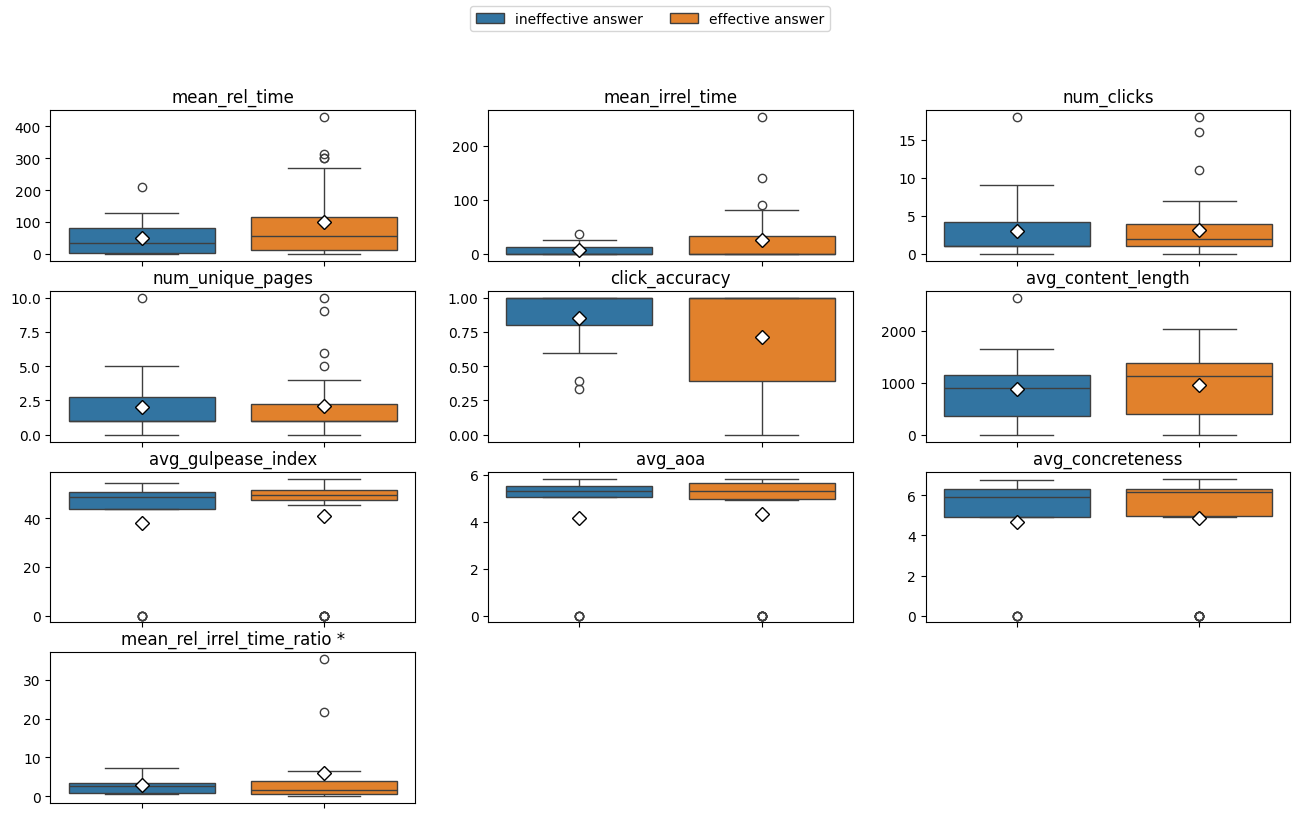

In [22]:
get_boxplots(final_answer_df, "information_distillation", categories, "effective_answer", artefact="answer", n_cols=3, n_rows=4, stats_df=sig_test_results)

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\scipy\stats\_stats_py.py:1127: RuntimeWarning: invalid value encountered in subtract
  a_zero_mean = a - mean


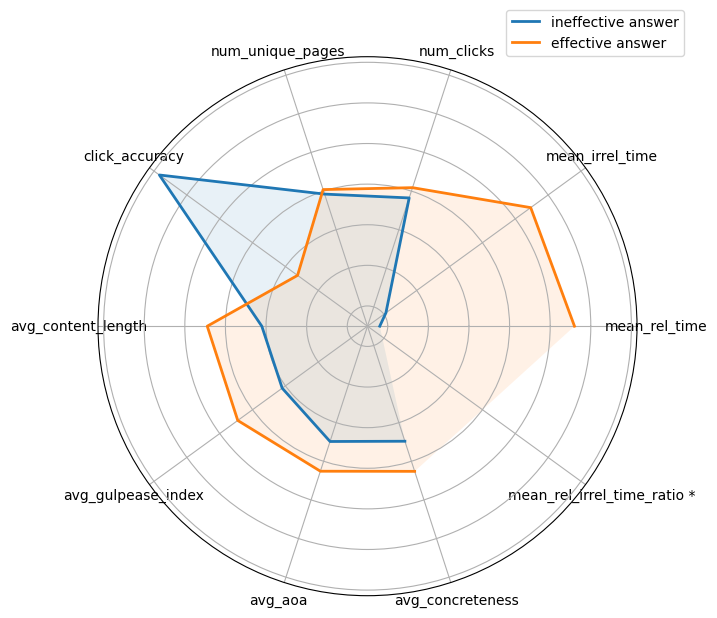

In [23]:
get_radar_plot(final_answer_df, "information_distillation", categories, artefact="answer", group="effective_answer", normalized=True, stats_df=sig_test_results)